In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import END, START
from langgraph.graph.state import StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage
import os
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
import os
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["LANGSMITH_API_KEY"]=os.getenv("LANGCHAIN_API_KEY")
os.environ["LANGSMITH_TRACING"]="true"
os.environ["LANGSMITH_PROJECT"]="TestProject"

In [3]:
from langchain.chat_models import init_chat_model
llm=init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.13', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x74765d6e4590>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x74765d6e5010>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [4]:
class State(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [5]:
## Graph With tool Call
from langchain_core.tools import tool

@tool
def add(a:float,b:float):
    """Add two number"""
    return a+b
tools=[add]
tool_node=ToolNode([add])

llm_with_tool=llm.bind_tools([add])

def call_llm_model(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}


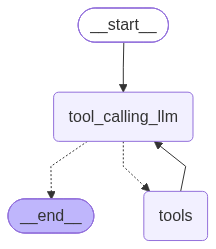

In [6]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def call_llm_model(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}
## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",call_llm_model)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
response=graph.invoke({"messages":"What is machine learning"})

In [8]:
response

{'messages': [HumanMessage(content='What is machine learning', additional_kwargs={}, response_metadata={}, id='fae482a0-73a6-4eb1-b875-a63e139cde74'),
  AIMessage(content='**Machine learning (ML)** is a branch of artificial intelligence that focuses on developing algorithms and statistical models that enable computers to improve their performance on a specific task by learning from data, rather than being explicitly programmed for every possible scenario.\n\n### Core Idea\n- **Data‑driven adaptation**: Instead of writing rules for every situation, we give the system a large set of examples (data) and let it discover patterns, relationships, or decision rules.\n- **Model training**: The algorithm iteratively adjusts its internal parameters to minimize the difference between its predictions and the actual outcomes in the training data.\n- **Generalization**: After training, the model should perform well on new, unseen data—this is the ultimate goal.\n\n### Key Components\n1. **Data**: Ra

In [9]:
response=graph.invoke({"messages":"what is 5 plus 20"})

In [10]:
response

{'messages': [HumanMessage(content='what is 5 plus 20', additional_kwargs={}, response_metadata={}, id='ee0ceaa8-b791-4849-8c22-cad137dfc393'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to use the add function.', 'tool_calls': [{'id': 'fc_f3bc0b64-33bc-4cd7-837d-ab7ea16baa8f', 'function': {'arguments': '{"a":5,"b":20}', 'name': 'add'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 127, 'total_tokens': 162, 'completion_time': 0.037999393, 'completion_tokens_details': {'reasoning_tokens': 9}, 'prompt_time': 0.008791024, 'prompt_tokens_details': None, 'queue_time': 0.375379357, 'total_time': 0.046790417}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_565badff47', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1efe5-50ad-79a0-b692-185fb2c77d59-0', tool_calls=[{'name': 'add', 'args': {'a': 5, 'b': 20}, 'id': 'fc_f3bc0b6